# Jobsheet 07 - Lab 3: Klasterisasi Pada Kompresi Citra dengan MiniBatchKMeans
**Mata Kuliah:** Pembelajaran Mesin (Machine Learning)  
**Institusi:** Jurusan Teknologi Informasi - Politeknik Negeri Malang  
**Topik:** Kuantisasi Warna (*Color Quantization*) dan Kompresi Citra Digital Menggunakan MiniBatchKMeans


## Langkah 0 - Import Library
Impor modul untuk pemrosesan array numerik, manipulasi gambar, dan algoritma `MiniBatchKMeans`.


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.datasets import load_sample_image
from sklearn.cluster import MiniBatchKMeans
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## Langkah 1 - Load Data Citra Sampel
Kita memuat citra sampel bunga dari pustaka Scikit-Learn menggunakan `load_sample_image("flower.jpg")`.


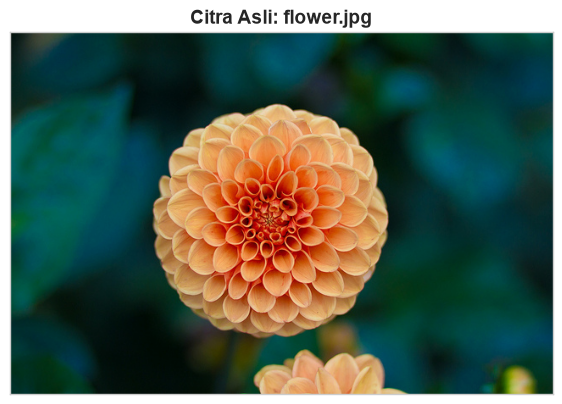

In [2]:
# Muat citra sampel bunga
flower = load_sample_image("flower.jpg")

plt.figure(figsize=(7, 5))
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)
plt.title("Citra Asli: flower.jpg", fontsize=14, fontweight='bold')
plt.show()


## Langkah 2 - Preprocessing Citra
Kita memeriksa resolusi dan dimensi array citra, lalu melakukan normalisasi intensitas piksel ke rentang $[0, 1]$ dan reshape menjadi matriks 2D berukuran $(N_{piksel}, 3)$.


In [3]:
# Check shape
print("Dimensi citra asli:", flower.shape)

# Normalize color
data = flower / 255.0

# Reshape
data = data.reshape(427 * 640, 3) # turn to 1D

print("Dimensi data setelah reshape:", data.shape)


Dimensi citra asli: (427, 640, 3)
Dimensi data setelah reshape: (273280, 3)


## Langkah 3 - Cek Sebaran Warna
Buat fungsi `plot_pixels` untuk memvisualisasikan sebaran warna piksel dalam ruang warna 3D (Red vs Green dan Red vs Blue).


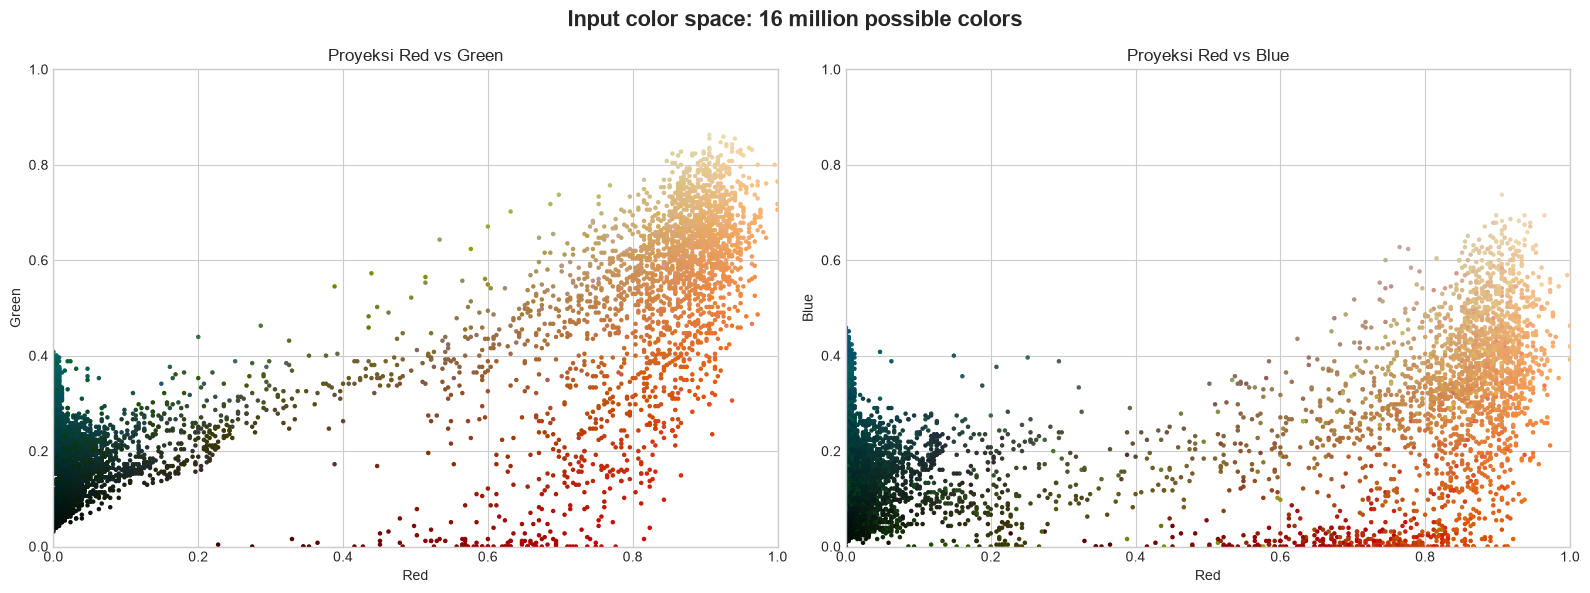

In [4]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data
    
    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.', s=20)
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))
    ax[0].set_title('Proyeksi Red vs Green', fontsize=12)

    ax[1].scatter(R, B, color=colors, marker='.', s=20)
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))
    ax[1].set_title('Proyeksi Red vs Blue', fontsize=12)

    fig.suptitle(title, size=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Panggil fungsi untuk mengetahui sebaran warna asli
plot_pixels(data, title='Input color space: 16 million possible colors')


## Langkah 4 - Klasterisasi Warna (Kompresi Warna ke 16 Warna)
Pada tahap ini kita melatih model `MiniBatchKMeans` dengan 16 klaster warna, lalu menggantikan setiap warna piksel dengan warna centroid terdekatnya.


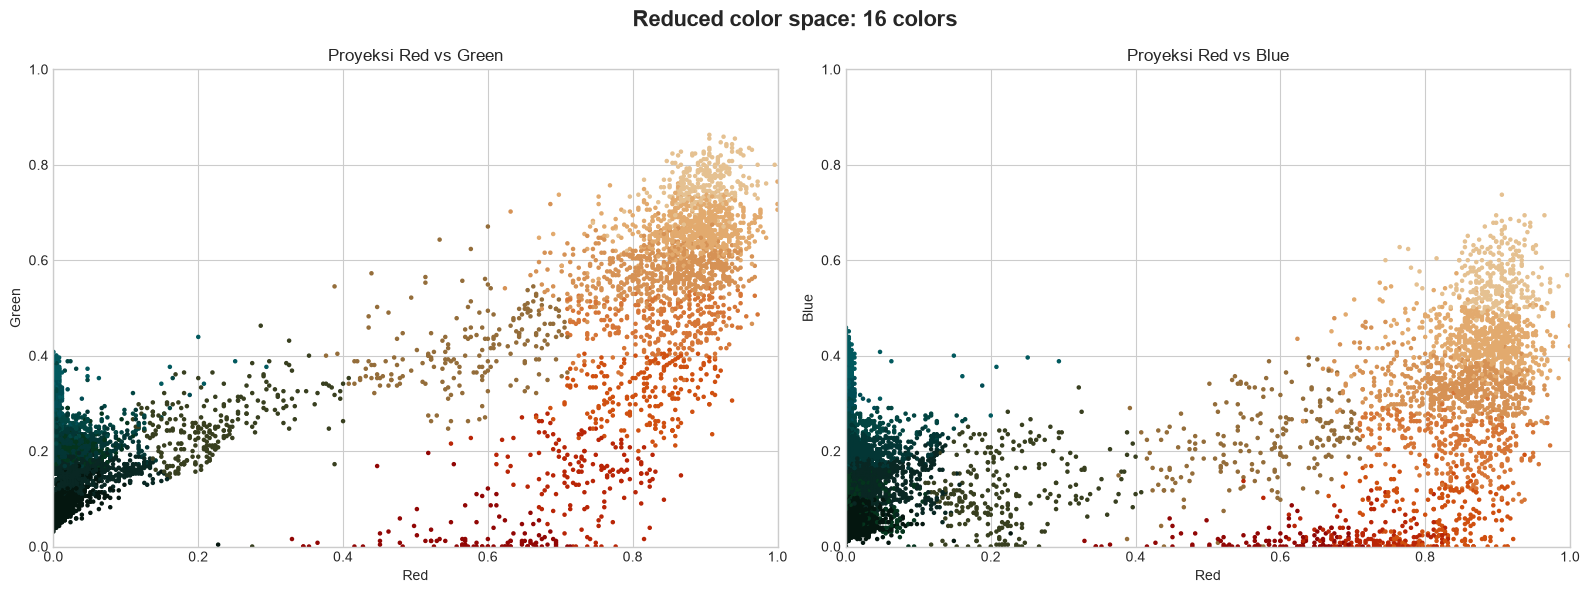

In [5]:
# Latih MiniBatchKMeans dengan 16 klaster
kmeans = MiniBatchKMeans(16, random_state=0, batch_size=2048)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

# Visualisasikan ruang warna tereduksi ke 16 warna
plot_pixels(data, colors=new_colors, title="Reduced color space: 16 colors")


## Langkah 5 - Rekonstruksi Citra & Komparasi Kualitas
Kita menyusun kembali array warna tereduksi ke bentuk dimensi citra asli $(427, 640, 3)$ dan menampilkan perbandingan visual berdampingan (*side-by-side*).


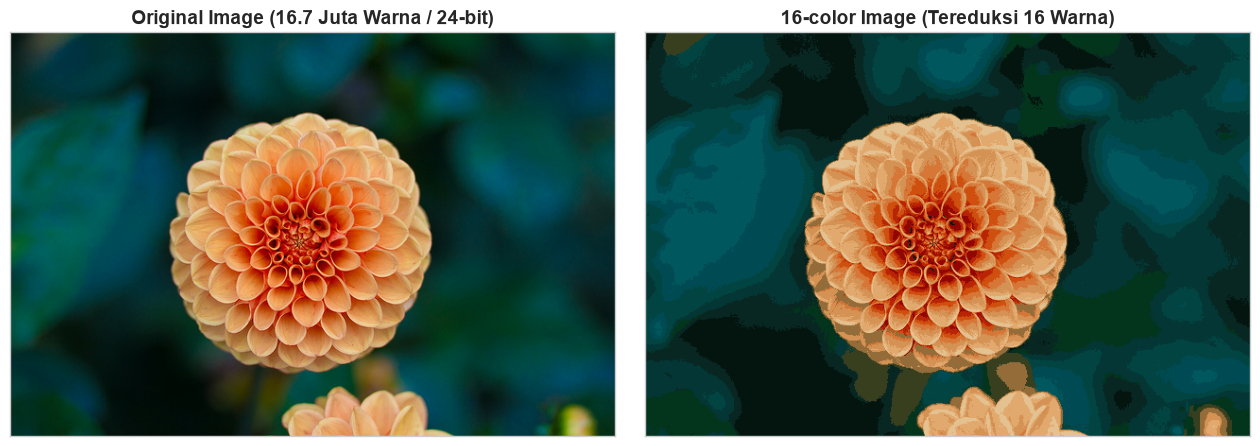

In [6]:
# Rekonstruksi citra dari 16 warna
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image (16.7 Juta Warna / 24-bit)', size=14, fontweight='bold')
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image (Tereduksi 16 Warna)', size=14, fontweight='bold')
plt.show()


### Pembahasan & Analisis Kompresi Citra:
1. **Mekanisme Kuantisasi Warna (*Color Quantization*)**: Dengan hanya mempertahankan 16 warna centroid, setiap piksel hanya memerlukan representasi indeks sebesar $\log_2(16) = 4$ bit (dibandingkan 24 bit per piksel pada citra RGB penuh).
2. **Efisiensi Penyimpanan**: Secara teoretis, ruang memori untuk representasi warna dapat dipangkas hingga $rac{4}{24} = 16.7\%$ dari ukuran aslinya.
3. **Kualitas Visual**: Meskipun jumlah warna berkurang drastis dari ratusan ribu warna unik menjadi hanya 16 warna, struktur bentuk kelopak bunga, gradasi dedaunan, dan kontras objek utama tetap dapat dikenali manusia secara sangat baik.
